In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

In [24]:
file_path = Path("C:/Users//adity//Downloads//TapLend_Data_Science_Assignment//data//AssessmentDataScientist.xlsx")

applications = pd.read_excel(file_path, sheet_name="Application Data")

loan_performance = pd.read_excel(file_path, sheet_name="Loan Performance")

print("Application data shape:", applications.shape)
print("Loan performance shape:", loan_performance.shape)

Application data shape: (647, 31)
Loan performance shape: (1285, 2)


c:\Users\adity\Downloads\TapLend_Data_Science_Assignment\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\adity\Downloads\TapLend_Data_Science_Assignment\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [25]:
print("Application Data Columns:")
print(applications.columns.tolist())

print("/nFirst five application records:")
display(applications.head())

Application Data Columns:
['customer_id', 'amount_requested', 'birth_date', 'status', 'residence_rent_or_own', 'monthly_rent_amount', 'bank_account_direct_deposit', 'application_when', 'loan_duration', 'payment_ach', 'num_payments', 'payment_amount', 'amount_approved', 'duration_approved', 'payment_amount_approved', 'address_zip', 'email', 'bank_routing_number', 'email_duration', 'residence_duration', 'bank_account_duration', 'payment_frequency', 'home_phone_type', 'other_phone_type', 'how_use_money', 'monthly_income_amount', 'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money']

First five application records:


,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,num_payments,payment_amount,amount_approved,duration_approved,payment_amount_approved,address_zip,email,bank_routing_number,email_duration,residence_duration,bank_account_duration,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,6,138.48,500,3,NaN,84118,WanitaGVinyard@gmail.com,124001545,1 year or more,6 months or less,6 months or less,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,13,77.39,500,6,NaN,84062,NatashaTTucker@yahoo.com,124000054,1 year or more,3+ years,3+ years,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,13,61.91,400,6,NaN,84119,AnneDCisneros@hotmail.com,124001545,1 year or more,7-12 months,1-2 years,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,8,108.48,500,4,NaN,84405,CatalinaRRoderick@hotmail.com,124002971,1 year or more,3+ years,7-12 months,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,8,65.09,300,4,NaN,84404,PhillipMSinn@aol.com,124002971,1 year or more,3+ years,6 months or less,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


In [26]:
print("Loan Performance Columns:")
print(loan_performance.columns.tolist())

print("/nFirst five loan records:")
display(loan_performance.head())

Loan Performance Columns:
['idLoan', 'flgGood']

First five loan records:


,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [27]:
print("Application data types:")
display(applications.dtypes)

print("/nLoan performance data types:")
display(loan_performance.dtypes)

Application data types:


customer_id                            object
amount_requested                        int64
birth_date                     datetime64[us]
status                                    str
residence_rent_or_own                    bool
monthly_rent_amount                     int64
bank_account_direct_deposit              bool
application_when               datetime64[us]
loan_duration                           int64
payment_ach                              bool
num_payments                            int64
payment_amount                        float64
amount_approved                         int64
duration_approved                       int64
payment_amount_approved               float64
address_zip                             int64
email                                     str
bank_routing_number                     int64
email_duration                            str
residence_duration                        str
bank_account_duration                     str
payment_frequency                 


Loan performance data types:


idLoan     str
flgGood    str
dtype: object

In [28]:
missing_values = applications.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(applications) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage
other_phone_type,285,44.05
payment_amount_approved,20,3.09
how_use_money,2,0.31
bank_account_duration,1,0.15


In [29]:
application_duplicates = applications.duplicated().sum()

loan_duplicates = loan_performance.duplicated().sum()

print("Duplicate application rows:", application_duplicates)
print("Duplicate loan performance rows:", loan_duplicates)

Duplicate application rows: 0
Duplicate loan performance rows: 0


In [30]:
print("Loan outcome counts:")

display(
    loan_performance["flgGood"].value_counts(dropna=False)
)

print("/nLoan outcome percentages:")

display(
    (
        loan_performance["flgGood"]
        .value_counts(normalize=True, dropna=False)
        * 100
    ).round(2)
)

Loan outcome counts:


flgGood
Good    769
Bad     516
Name: count, dtype: int64


Loan outcome percentages:


flgGood
Good    59.84
Bad     40.16
Name: proportion, dtype: float64

In [31]:
applications["customer_key"] = (
    applications["customer_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

loan_performance["customer_key"] = (
    loan_performance["idLoan"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.split("-")
    .str[0]
)

In [32]:
merged_data = loan_performance.merge(
    applications,
    on="customer_key",
    how="left",
    indicator=True,
    validate="many_to_one",
    suffixes=("_loan", "_application")
)

print("Total loan records:", len(merged_data))

print("/nMerge results:")
display(merged_data["_merge"].value_counts())

Total loan records: 1285

Merge results:


_merge
both          656
left_only     629
right_only      0
Name: count, dtype: int64

In [40]:
Path("C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs").mkdir(parents=True, exist_ok=True)

In [43]:
unmatched_loans = merged_data.loc[
    merged_data["_merge"] == "left_only",
    ["idLoan", "customer_key", "flgGood"]
].copy()

print("Number of unmatched loans:", len(unmatched_loans))

display(unmatched_loans.head(20))

unmatched_loans.to_csv(
    "C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs/unmatched_loans.csv",
    index=False
)

Number of unmatched loans: 629


,idLoan,customer_key,flgGood
124,00413198E8-01,00413198E8,Bad
199,4E6BB20BE7-01,4E6BB20BE7,Good
209,2101486E84-01,2101486E84,Bad
544,0902431691-01,0902431691,Bad
642,A0A2AF6279-01,A0A2AF6279,Bad
643,7E0DE8F17D-01,7E0DE8F17D,Bad
646,A48ABA44AF-01,A48ABA44AF,Good
647,30094A8999-01,30094A8999,Bad
648,A3853EB675-01,A3853EB675,Good
649,558F3B7260-01,558F3B7260,Bad


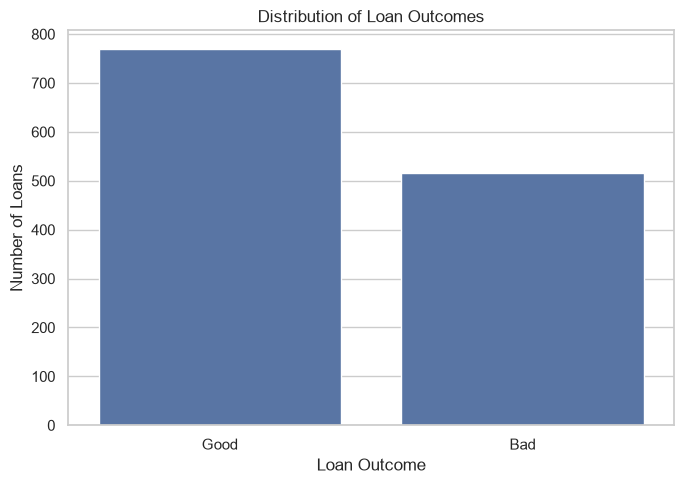

In [45]:
outcome_counts = loan_performance["flgGood"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=outcome_counts.index,
    y=outcome_counts.values
)

plt.title("Distribution of Loan Outcomes")
plt.xlabel("Loan Outcome")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.savefig("C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs/loan_outcome_distribution.png", dpi=300)
plt.show()

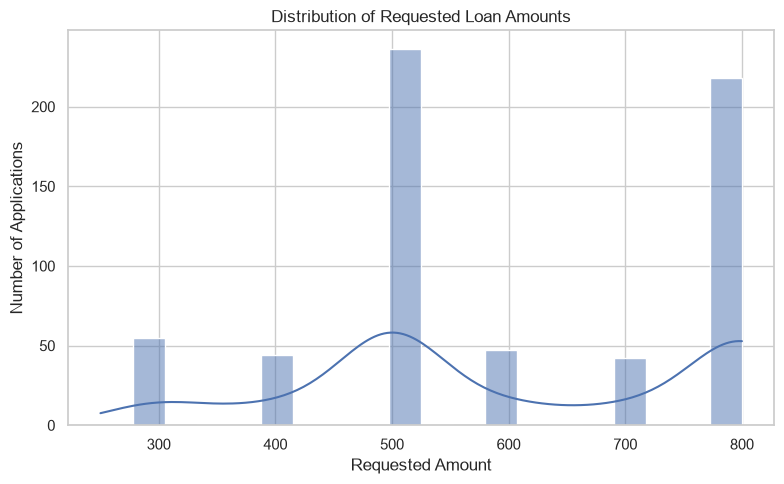

In [47]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=applications,
    x="amount_requested",
    bins=20,
    kde=True
)

plt.title("Distribution of Requested Loan Amounts")
plt.xlabel("Requested Amount")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.savefig("C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs//requested_loan_amounts.png", dpi=300)
plt.show()

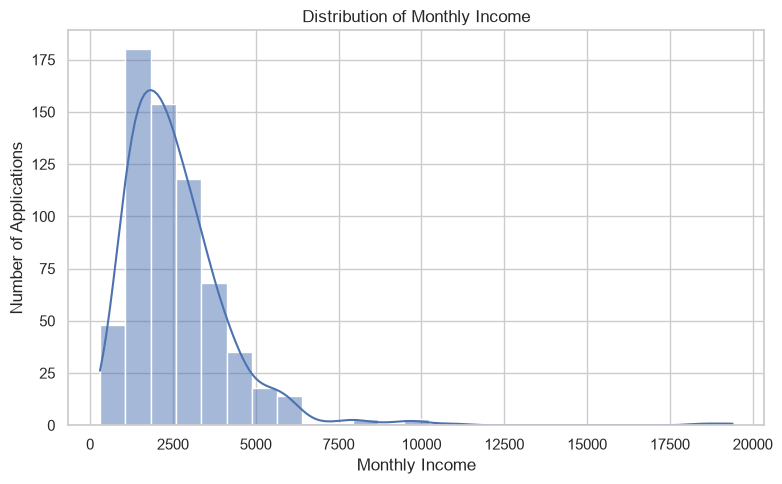

In [48]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=applications,
    x="monthly_income_amount",
    bins=25,
    kde=True
)

plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.savefig("C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs/monthly_income_distribution.png", dpi=300)
plt.show()

Matched records: 656


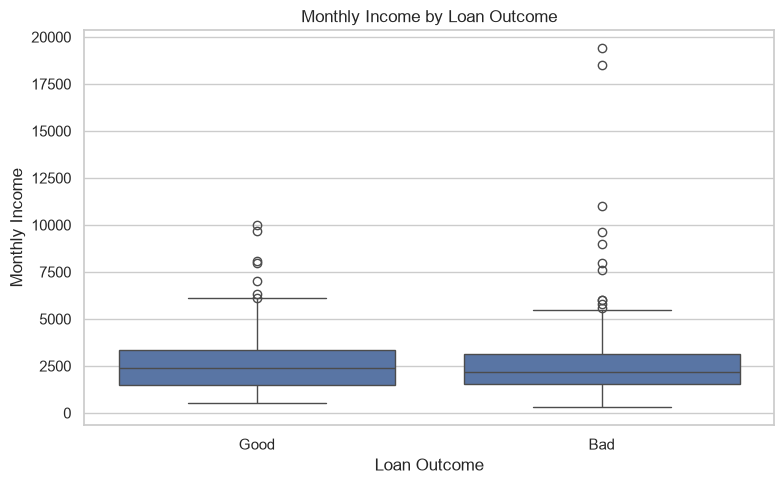

In [49]:
matched_data = merged_data.loc[
    merged_data["_merge"] == "both"
].copy()

print("Matched records:", len(matched_data))

outcome_order = ["Good", "Bad"]

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=matched_data,
    x="flgGood",
    y="monthly_income_amount",
    order=outcome_order
)

plt.title("Monthly Income by Loan Outcome")
plt.xlabel("Loan Outcome")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.savefig("C:/Users/adity/Downloads/TapLend_Data_Science_Assignment/outputs/income_by_outcome.png", dpi=300)
plt.show()